# v6 hydrostatics setup

Reuses the completed v5 component-loading solve, analytical-box benchmark, buoyancy and CG checks, and timestamped exports through `../study.py`. Historical notebooks and results are preserved. The active propulsion model remains `prop_motor_battery/willmarley.ipynb`.

**Geometry ready:** the supplied v6 STEP has a reviewed, watertight flotation envelope in `geometry/`. **Loading:** seven filled v6 components total 153.595 lb; thirteen blank weights are excluded as authorized by the user. No v5 weights are assumed to describe v6. Follow [the setup checklist](README.md) for inputs, assumptions and the completed partial-loading run.


In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'prop_motor_battery/willmarley.ipynb').is_file())
HYDRO = ROOT / 'hull/hydrostatics'
STUDY = HYDRO / 'v6-2026-11-11'
os.environ.setdefault('MPLCONFIGDIR', str(STUDY / '.mpl-cache'))
local_site = HYDRO / f'.venv/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages'
if local_site.is_dir() and str(local_site) not in sys.path:
    sys.path.insert(0, str(local_site))
if str(HYDRO) not in sys.path:
    sys.path.insert(0, str(HYDRO))
import importlib
import study
importlib.reload(study)

DENSITY_KG_M3 = 998.2  # Proposed freshwater condition; confirm for v6.
ALLOW_BLANK_MASSES = True  # User authorized excluding missing weights for this v6 case.


## Geometry and loading

The cached v6 geometry is ready. `prepare_geometry.py` reuses the v5 method with reviewed v6 exterior faces 41–44, 50, 51 and 53, and a new cap from rim face 46's outer wire. The raw rim face is invalid; the newly capped flotation solid passes validity, watertightness, winding and volume checks. See the README for regeneration and source inspection. Use full-scale metres in NavalToolbox, with X = CAD Y, Y = −CAD X and Z unchanged.

Fill `component-masses.csv` with pounds and component CGs in inches: X transverse, Y forward from transom, Z up from aft keel. The component list began as the v5 checklist; the supplied v6 masses and positions are used here. The current case explicitly allows partial loading. Excluded rows are listed in the outputs; set `ALLOW_BLANK_MASSES = False` to require all listed masses.


Total supplied mass: 153.595 lb / 69.670 kg
Whole-boat CAD CG (X transverse, Y forward, Z up), inches: [ 0.06582 27.30836  5.54067]
PARTIAL LOADING: 13 blank rows excluded:
Analytical box maximum relative error: 6.103515624955591e-05
Mass balance error: 0.00371%
Saved results: hull/hydrostatics/v6-2026-11-11/results/navaltoolbox-20261112T004048182860Z
Saved results: hull/hydrostatics/v6-2026-11-11/results/navaltoolbox-20261112T004048182860Z


Matplotlib is building the font cache; this may take a moment.


,csv_line,component_id,label,mass_lbs,cg_x_in,cg_y_in,cg_z_in,source,notes
0,2,printed_shell,Printed hull shell (CSV line 2),25.000,0.000,31.197,4.624,cad,Include integral printed hardpoints
1,8,battery_1,Battery 1 (CSV line 8),30.865,0.000,6.400,6.100,cad,Confirm battery count and v6 component CG
2,9,battery_2,Battery 2 (CSV line 9),30.865,0.000,18.195,6.098,cad,Confirm battery count and v6 component CG
3,10,battery_3,Battery 3 (CSV line 10),30.865,0.000,30.000,6.100,cad,Confirm battery count and v6 component CG
4,11,motor_port,Port motor assembly (CSV line 11),3.000,-5.143,42.033,3.442,cad,Include propeller strut and mounts unless list...
5,12,motor_starboard,Starboard motor assembly (CSV line 12),3.000,5.143,42.033,3.442,cad,Include propeller strut and mounts unless list...
6,20,payload_front,Front payload (CSV line 20),30.000,0.337,49.241,5.000,cad,Exclude equipment already listed


,csv_line,component_id,component
0,3,glass_resin_finish,Fiberglass resin fairing and paint
1,4,tube_port,Port tube
2,5,tube_starboard,Starboard tube
3,6,backbone,Backbone and frame
4,7,baseboard,Baseboard
5,13,esc_port,Port motor controller
6,14,esc_starboard,Starboard motor controller
7,15,electronics_enclosure,Electronics enclosure
8,16,electronics,Electronics and power distribution
9,17,sensor_tower,Sensor tower and sensors


,Baseline
mass_lb,153.595
mass_kg,69.66952
draft_aft_in,6.32998
draft_midship_in,5.194336
draft_forward_in,4.058692
trim_bow_down_deg,-1.806834
heel_deg,0.603931
freeboard_min_in,5.559677
waterline_length_in,66.706525
submerged_length_in,66.706525


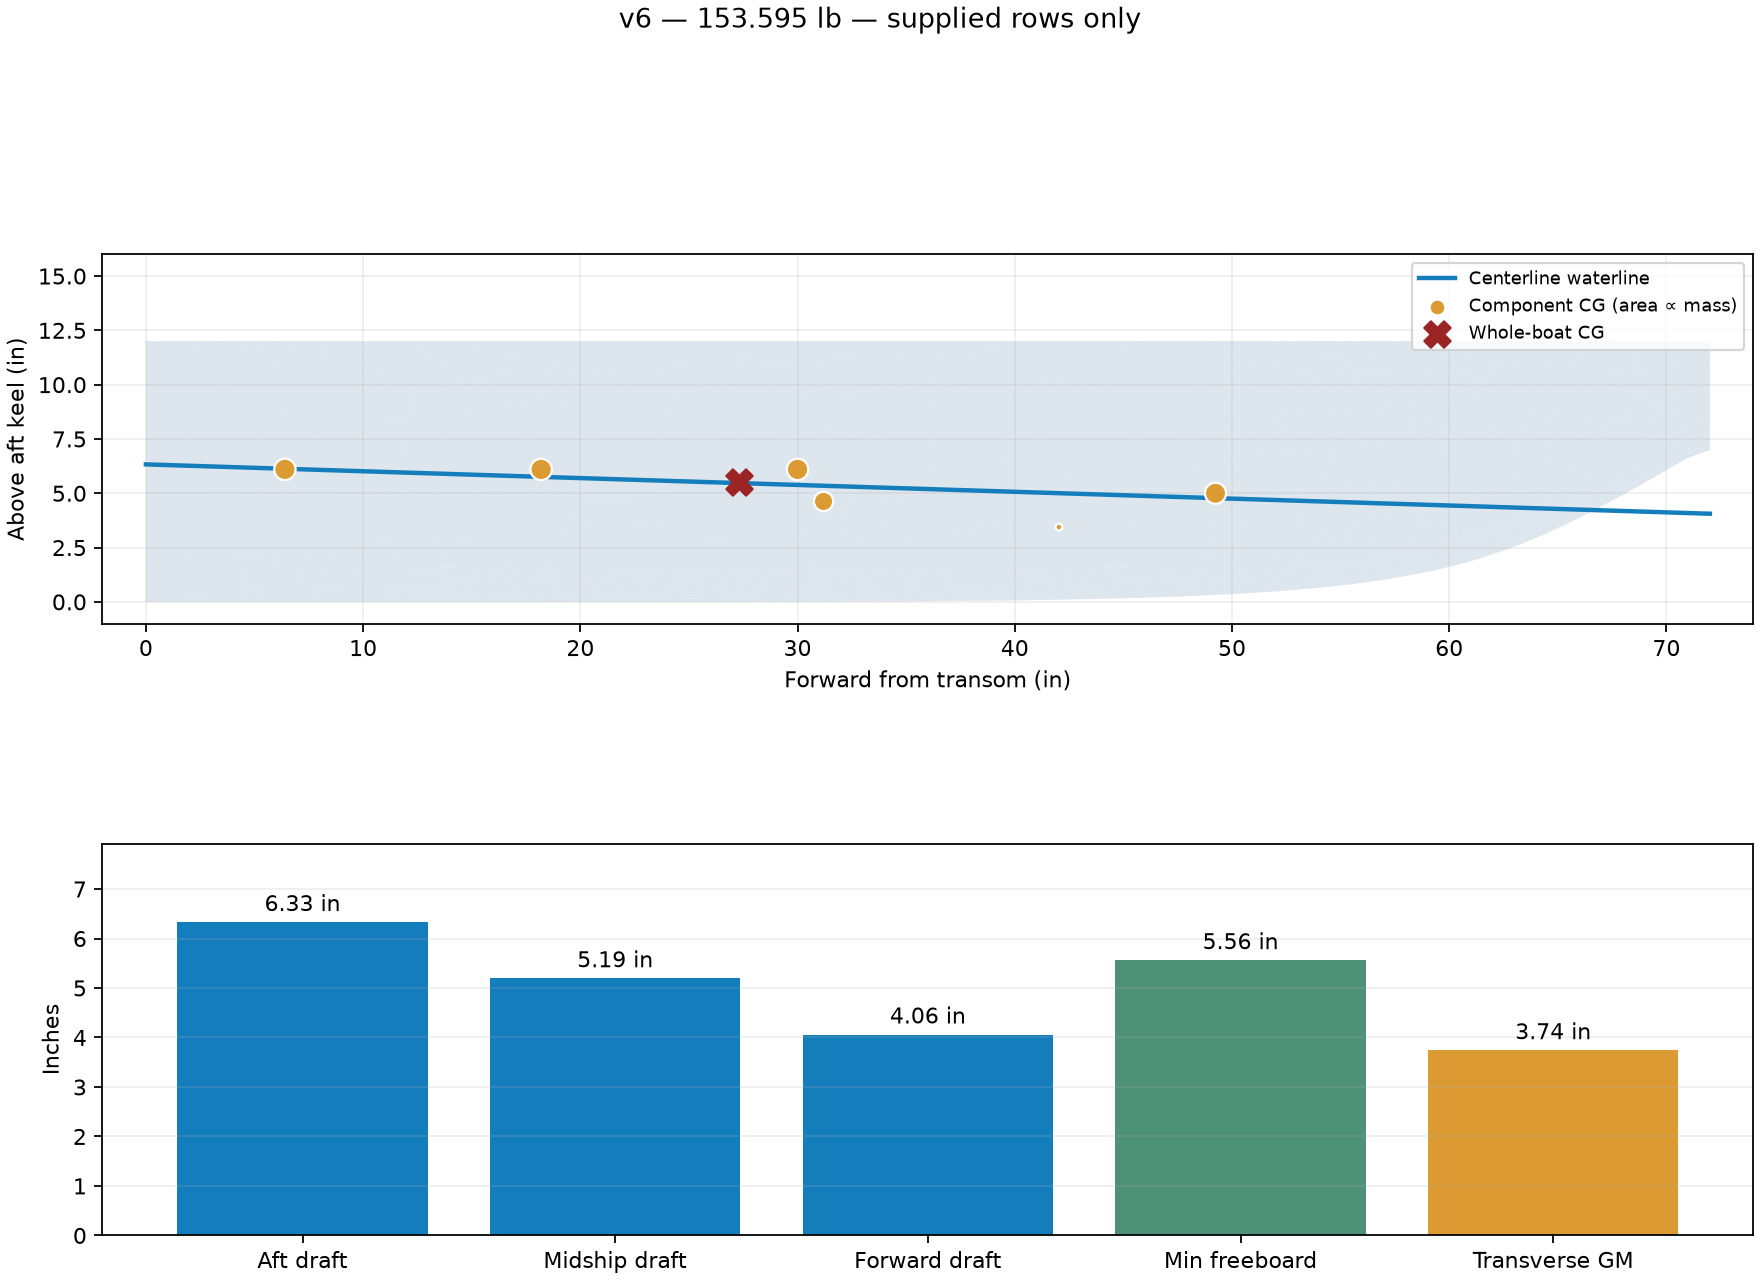

In [2]:
output = study.run_study(STUDY, density_kg_m3=DENSITY_KG_M3,
                         allow_blank_masses=ALLOW_BLANK_MASSES)
print('Saved results:', output.relative_to(ROOT))


## Boat attitude with level water

The waterline stays horizontal; the boat rotates to the calculated trim. This side view shows **trim only** (heel is omitted). The outline comes from the v6 flotation mesh, with equal horizontal and vertical scales. Negative solver trim means bow up.


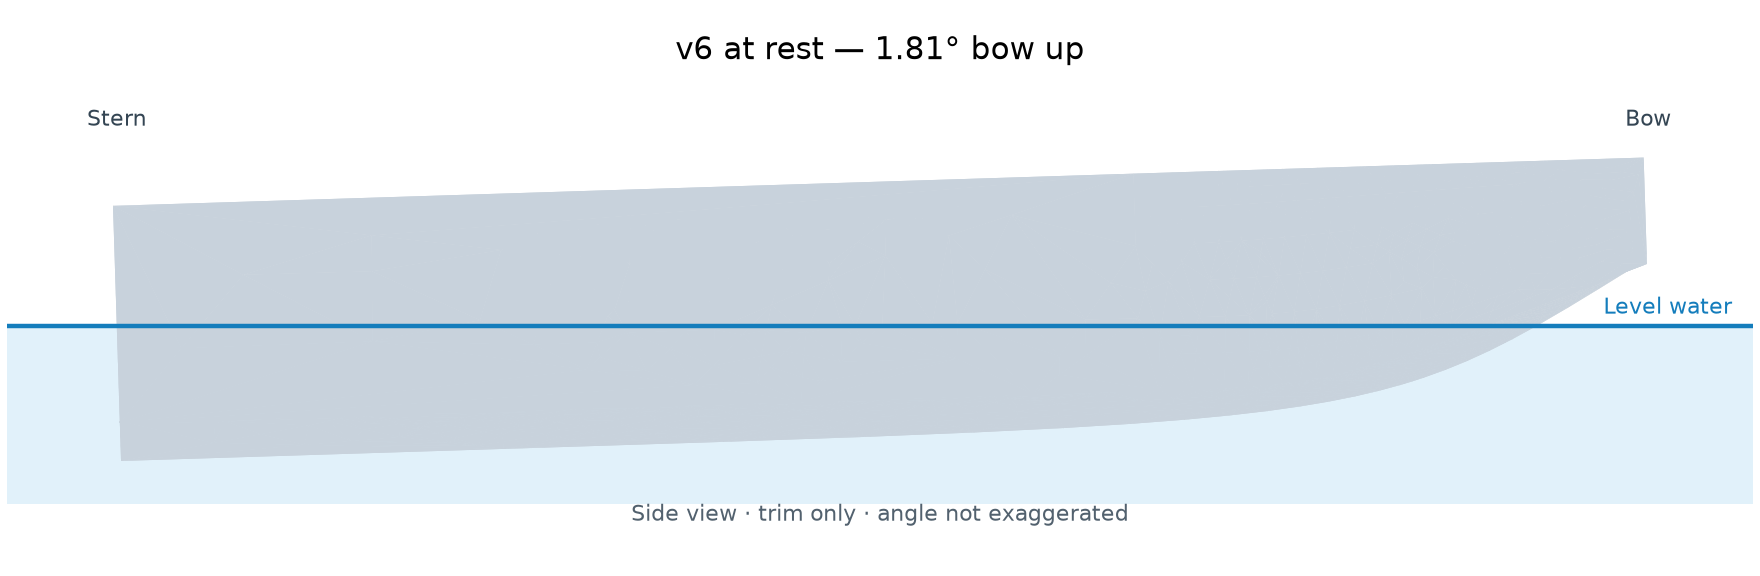

In [3]:
import struct
import hashlib
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from IPython.display import Image, display

saved = json.loads((output / 'study.json').read_text())
r = saved['result']
mesh_bytes = (STUDY / 'geometry/hull-envelope.stl').read_bytes()
assert hashlib.sha256(mesh_bytes).hexdigest() == saved['geometry']['stl_sha256']
triangle_count = struct.unpack_from('<I', mesh_bytes, 80)[0]
triangles = np.array([
    struct.unpack_from('<12fH', mesh_bytes, 84 + 50*i)[3:12]
    for i in range(triangle_count)
]).reshape(-1, 3, 3) / study.IN_TO_M

# Rotate the hull, rather than the water. Shift the aft waterline to Z = 0.
# Positive drawing angle is bow up, opposite the solver's trim convention.
angle = np.deg2rad(-r['trim_bow_down_deg'])
x = triangles[:, :, 0] - triangles[:, :, 0].min()
z = triangles[:, :, 2] - r['draft_aft_in']
world_x = x*np.cos(angle) - z*np.sin(angle)
world_z = x*np.sin(angle) + z*np.cos(angle)
side = np.stack([world_x, world_z], axis=-1)

# The reported aft/forward waterline references must rotate to level water.
length = float(x.max())
water_z = np.array([0, length])*np.sin(angle) + (
    np.array([r['draft_aft_in'], r['draft_forward_in']]) - r['draft_aft_in']
)*np.cos(angle)
assert np.allclose(water_z, 0, atol=.01), 'Drafts and trim disagree.'

fig, ax = plt.subplots(figsize=(11, 3.6), layout='constrained')
left, right = float(world_x.min()) - 5, float(world_x.max()) + 5
bottom, top = min(float(world_z.min()) - 2, -3), float(world_z.max()) + 4
ax.axhspan(bottom, 0, color='#e1f1fa', zorder=0)
ax.add_collection(PolyCollection(side, facecolors='#c8d2dc', edgecolors='none', zorder=2))
ax.axhline(0, color='#147dbc', linewidth=2, zorder=3)
ax.text(right - 1, .6, 'Level water', color='#147dbc', ha='right')
ax.text(0, float(world_z.max()) + 1.5, 'Stern', ha='center', color='#344553')
ax.text(length, float(world_z.max()) + 1.5, 'Bow', ha='center', color='#344553')
attitude = 'bow up' if r['trim_bow_down_deg'] < 0 else 'bow down' if r['trim_bow_down_deg'] > 0 else 'level'
ax.set_title(f"v6 at rest — {abs(r['trim_bow_down_deg']):.2f}° {attitude}", fontsize=14)
ax.set(xlim=(left, right), ylim=(bottom, top), aspect='equal')
ax.axis('off')
ax.text(.5, -.04, 'Side view · trim only · angle not exaggerated', transform=ax.transAxes,
        ha='center', color='#52616e', fontsize=10)
drawing_file = output / 'level-water-side-view.png'
fig.savefig(drawing_file, dpi=160, facecolor='white')
plt.close(fig)
display(Image(filename=str(drawing_file)))
